# Student Performance and Risk Predictor
## Machine Learning Mini Project

### Project Overview
In educational institutions, predicting a student's final academic performance early in the semester enables timely academic support and counseling before final examinations.

In this mini project, we address two core machine learning tasks using the Kaggle dataset:
1. **Regression Task:** Predicting the student's continuous final examination score (`Final_Score`) based on attendance, midterm marks, quiz scores, assignment averages, project marks, and foundational subject scores (Math, Reading, Writing, Science) using **Multiple Linear Regression** and **Decision Tree Regressor**.
2. **Classification Task:** Identifying students who are academically **At-Risk** of failing (`Grade == 'F'`) using a **Decision Tree Classifier**.
3. **Single-Screen Web Dashboard:** Providing an interactive unified screen (both as an in-notebook widget and as a standalone web page `dashboard.html`) to test live predictions with sliders.

We train our models on `train.csv` (8,000 student records) and evaluate them on `test.csv` (2,000 student records).


## Step 1: Importing Required Libraries
We import Python libraries for data manipulation (`pandas`, `numpy`), data visualization (`matplotlib`, `seaborn`), and machine learning algorithms and evaluation metrics (`scikit-learn`).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Scikit-learn imports for regression, classification, and metrics
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("All required libraries imported successfully.")

All required libraries imported successfully.


## Step 2: Loading and Inspecting the Datasets
We load `train.csv` (8,000 records) and `test.csv` (2,000 records). 
We verify their shapes, examine column names, and view the first 5 records of the training set.


In [2]:
# Loading training and testing datasets
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

print("Training Dataset Shape: ", train_df.shape)
print("Testing Dataset Shape:  ", test_df.shape)
print("\nColumns in Dataset:")
print(list(train_df.columns))

print("\nFirst 5 Records of Training Set:")
train_df[['Student_ID', 'Gender', 'Department', 'Attendance (%)', 'Midterm_Score', 'Final_Score', 'Total_Score', 'Grade']].head()

Training Dataset Shape:  (8000, 21)
Testing Dataset Shape:   (2000, 21)

Columns in Dataset:
['Student_ID', 'First_Name', 'Last_Name', 'Email', 'Gender', 'Age', 'Department', 'Attendance (%)', 'Midterm_Score', 'Final_Score', 'Assignments_Avg', 'Quizzes_Avg', 'Participation_Score', 'Projects_Score', 'Total_Score', 'Grade', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score', 'science_score']

First 5 Records of Training Set:


### Dataset Schema and Features
The dataset contains 21 features per student record:
- **Identifiers:** `Student_ID`, `First_Name`, `Last_Name`, `Email` (excluded from model training).
- **Demographics & Background:** `Gender`, `Age`, `Department`, `test_preparation_course`.
- **Academic Performance Metrics:** `Attendance (%)`, `Midterm_Score`, `Assignments_Avg`, `Quizzes_Avg`, `Participation_Score`, `Projects_Score`.
- **Foundational Subject Scores:** `math_score`, `reading_score`, `writing_score`, `science_score`.
- **Target Variables:**
  - `Final_Score`: Continuous score (0 to 100) used as the regression target.
  - `Total_Score`: Overall course score.
  - `Grade`: Letter grade assigned ('A', 'B', 'C', 'D', 'F'). Students with grade 'F' form the binary classification target (`At_Risk = 1`).


In [3]:
# Statistical summary of numerical columns in training set
print("Training Data Summary Statistics:")
train_df.describe().round(2)

Training Data Summary Statistics:


## Step 3: Data Cleaning and Preprocessing
Data cleaning is an essential preprocessing step:
1. **Handling Data Types:** In `train.csv`, the column `math_score` contains escape characters (`\t41`) causing it to be parsed as a string. We strip the escape sequence, convert it to float, and impute any missing entries using the training median (58.0).
2. **Missing Values & Duplicates:** We check for null entries and duplicate rows across both sets.
3. **Categorical Feature Encoding:** We map `Gender` (Male: 0, Female: 1) and encode `Department` (CS: 0, Engineering: 1, Business: 2, Mathematics: 3).
4. **Target Definition:** We define `At_Risk = 1` for students with `Grade == 'F'` and `0` otherwise.


In [4]:
# 1. Cleaning math_score in both train and test sets
for df in [train_df, test_df]:
    df['math_score'] = pd.to_numeric(
        df['math_score'].astype(str).str.replace(r'\\t|\t', '', regex=True), 
        errors='coerce'
    )
    median_math = train_df['math_score'].median()
    df['math_score'] = df['math_score'].fillna(median_math)

# 2. Checking missing values
print("Missing values in Training Set:")
print(train_df[['Attendance (%)', 'Midterm_Score', 'Final_Score', 'math_score', 'science_score', 'Grade']].isnull().sum())

# 3. Categorical encoding
dept_mapping = {'CS': 0, 'Engineering': 1, 'Business': 2, 'Mathematics': 3}
for df in [train_df, test_df]:
    df['Gender_Code'] = (df['Gender'] == 'Female').astype(int)
    df['Department_Code'] = df['Department'].map(dept_mapping).fillna(0).astype(int)
    df['At_Risk'] = (df['Grade'] == 'F').astype(int)

print("\nCategorical encoding completed.")
print("Training At-Risk distribution:\n", train_df['At_Risk'].value_counts())
print("Testing At-Risk distribution:\n", test_df['At_Risk'].value_counts())

Missing values in Training Set:
Attendance (%)    0
Midterm_Score     0
Final_Score       0
math_score        0
science_score     0
Grade             0
dtype: int64

Categorical encoding completed.
Training At-Risk distribution:
 At_Risk
0    6678
1    1322
Name: count, dtype: int64
Testing At-Risk distribution:
 At_Risk
0    1670
1     330
Name: count, dtype: int64


## Step 4: Exploratory Data Analysis (EDA)
We conduct exploratory data analysis to visualize score distributions, examine the correlation matrix, compare subject-level proficiencies, and understand the factors influencing student performance.


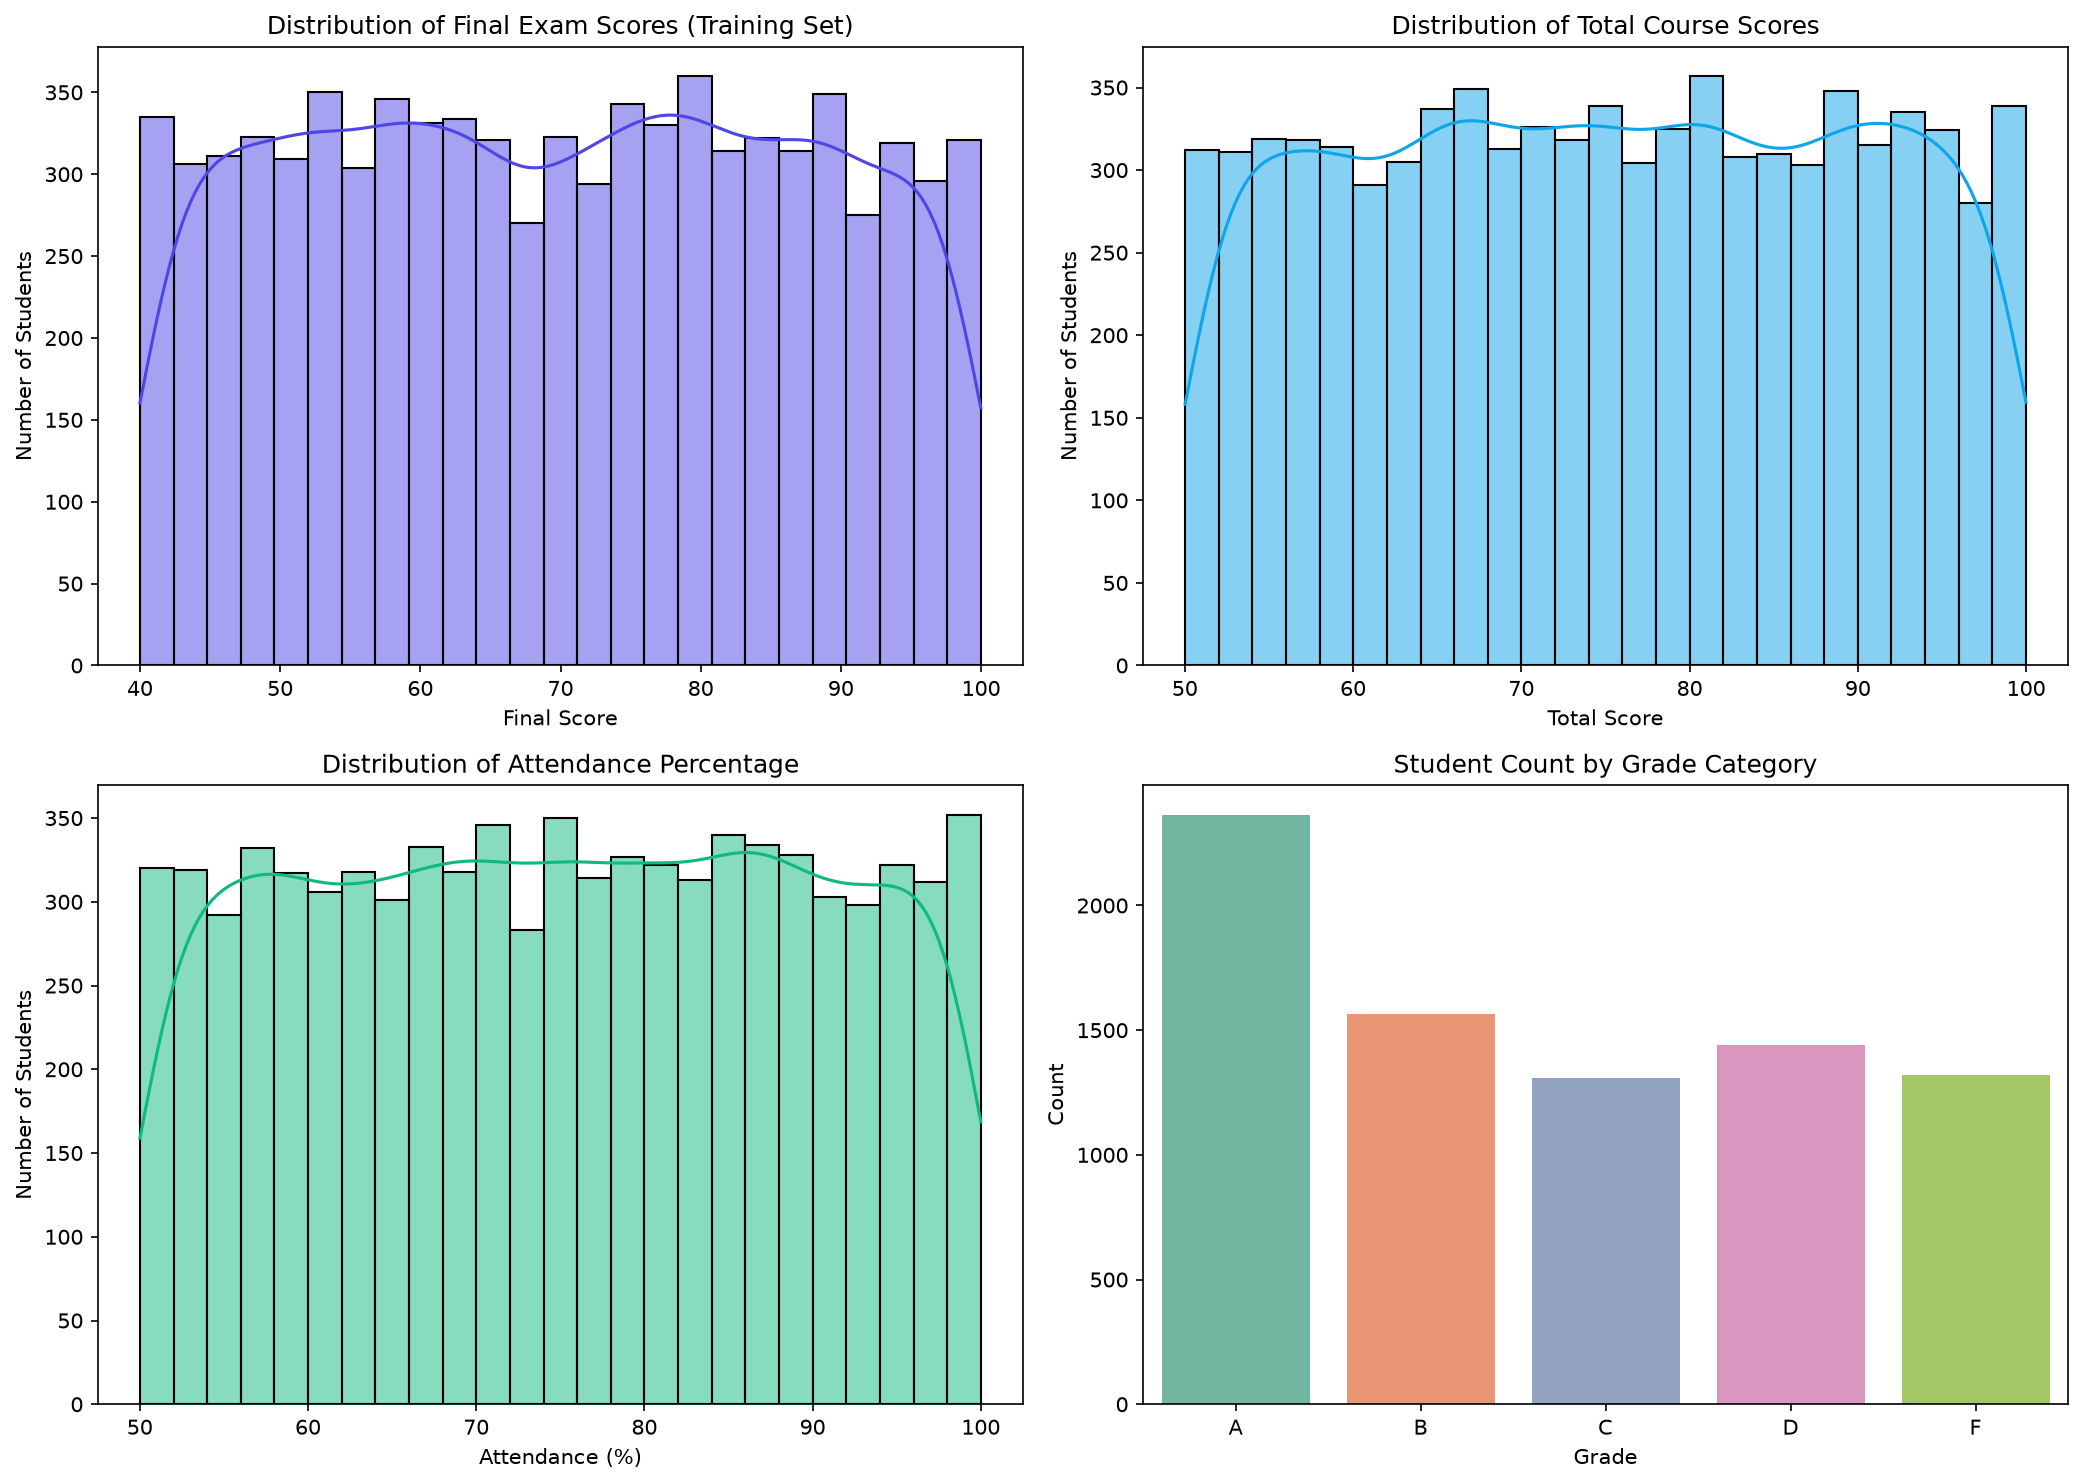

In [5]:
# Plot 1: Score Distributions and Grade Counts
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Final Score Distribution
sns.histplot(train_df['Final_Score'], kde=True, color='#4f46e5', bins=25, ax=axes[0, 0])
axes[0, 0].set_title('Distribution of Final Exam Scores (Training Set)')
axes[0, 0].set_xlabel('Final Score')
axes[0, 0].set_ylabel('Number of Students')

# Total Score Distribution
sns.histplot(train_df['Total_Score'], kde=True, color='#0ea5e9', bins=25, ax=axes[0, 1])
axes[0, 1].set_title('Distribution of Total Course Scores')
axes[0, 1].set_xlabel('Total Score')
axes[0, 1].set_ylabel('Number of Students')

# Attendance Rate Distribution
sns.histplot(train_df['Attendance (%)'], kde=True, color='#10b981', bins=25, ax=axes[1, 0])
axes[1, 0].set_title('Distribution of Attendance Percentage')
axes[1, 0].set_xlabel('Attendance (%)')
axes[1, 0].set_ylabel('Number of Students')

# Student Grade Counts
grade_order = ['A', 'B', 'C', 'D', 'F']
sns.countplot(x='Grade', data=train_df, order=grade_order, palette='Set2', ax=axes[1, 1])
axes[1, 1].set_title('Student Count by Grade Category')
axes[1, 1].set_xlabel('Grade')
axes[1, 1].set_ylabel('Count')

plt.tight_layout()
plt.savefig('figures/1_score_distributions.png', dpi=300)
plt.show()

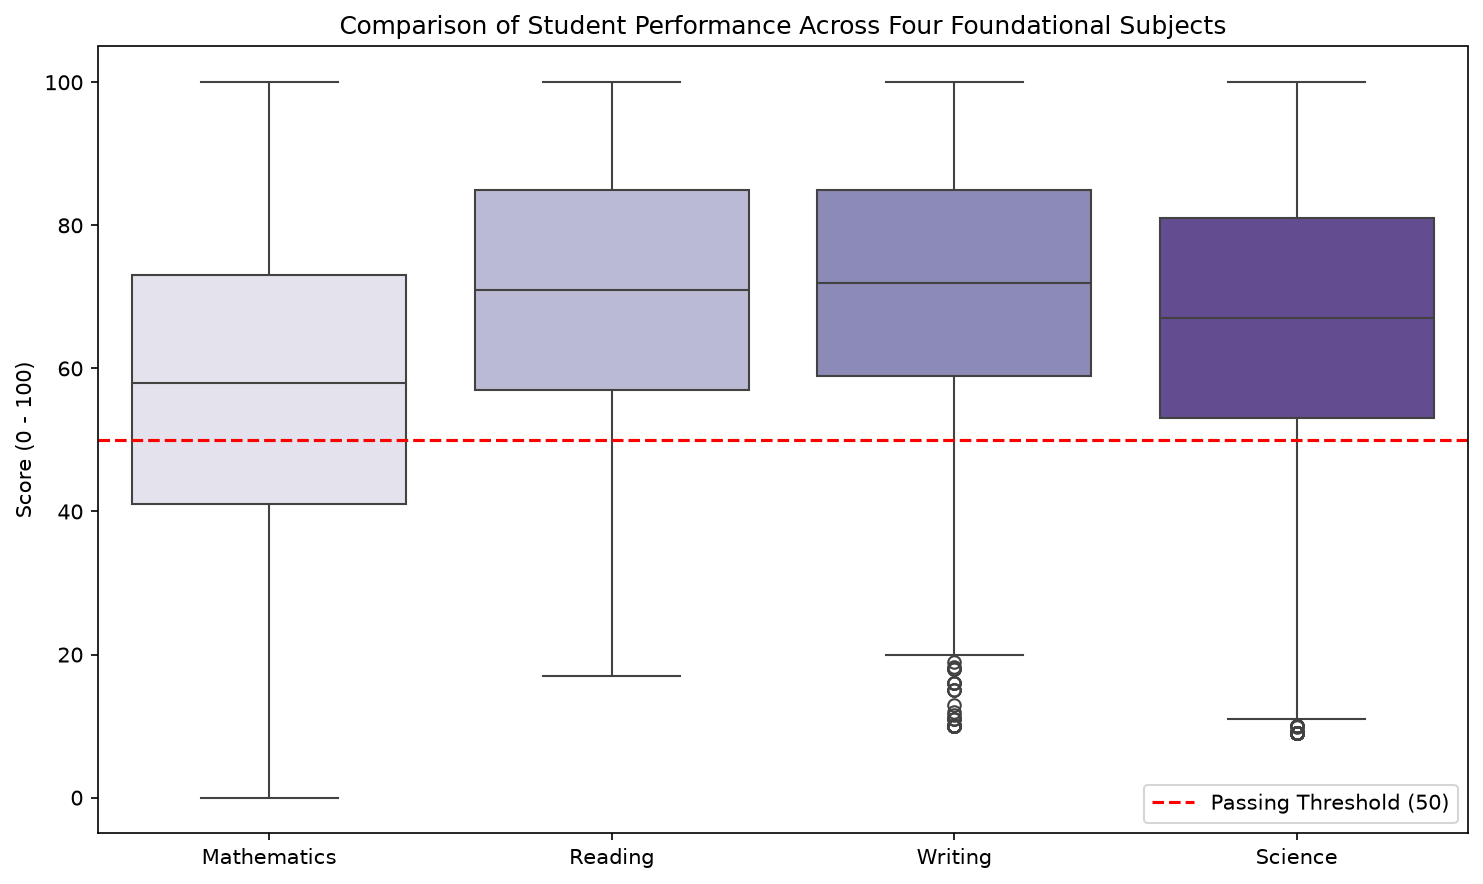

In [6]:
# Plot 2: Subject Performance Comparison (Math, Reading, Writing, Science)
subjects = ['math_score', 'reading_score', 'writing_score', 'science_score']
subject_labels = ['Mathematics', 'Reading', 'Writing', 'Science']

plt.figure(figsize=(10, 6))
sns.boxplot(data=train_df[subjects], palette='Purples')
plt.title('Comparison of Student Performance Across Four Foundational Subjects')
plt.xticks(ticks=range(4), labels=subject_labels)
plt.ylabel('Score (0 - 100)')
plt.axhline(50, color='red', linestyle='--', label='Passing Threshold (50)')
plt.legend()
plt.tight_layout()
plt.savefig('figures/2_subject_comparison.png', dpi=300)
plt.show()

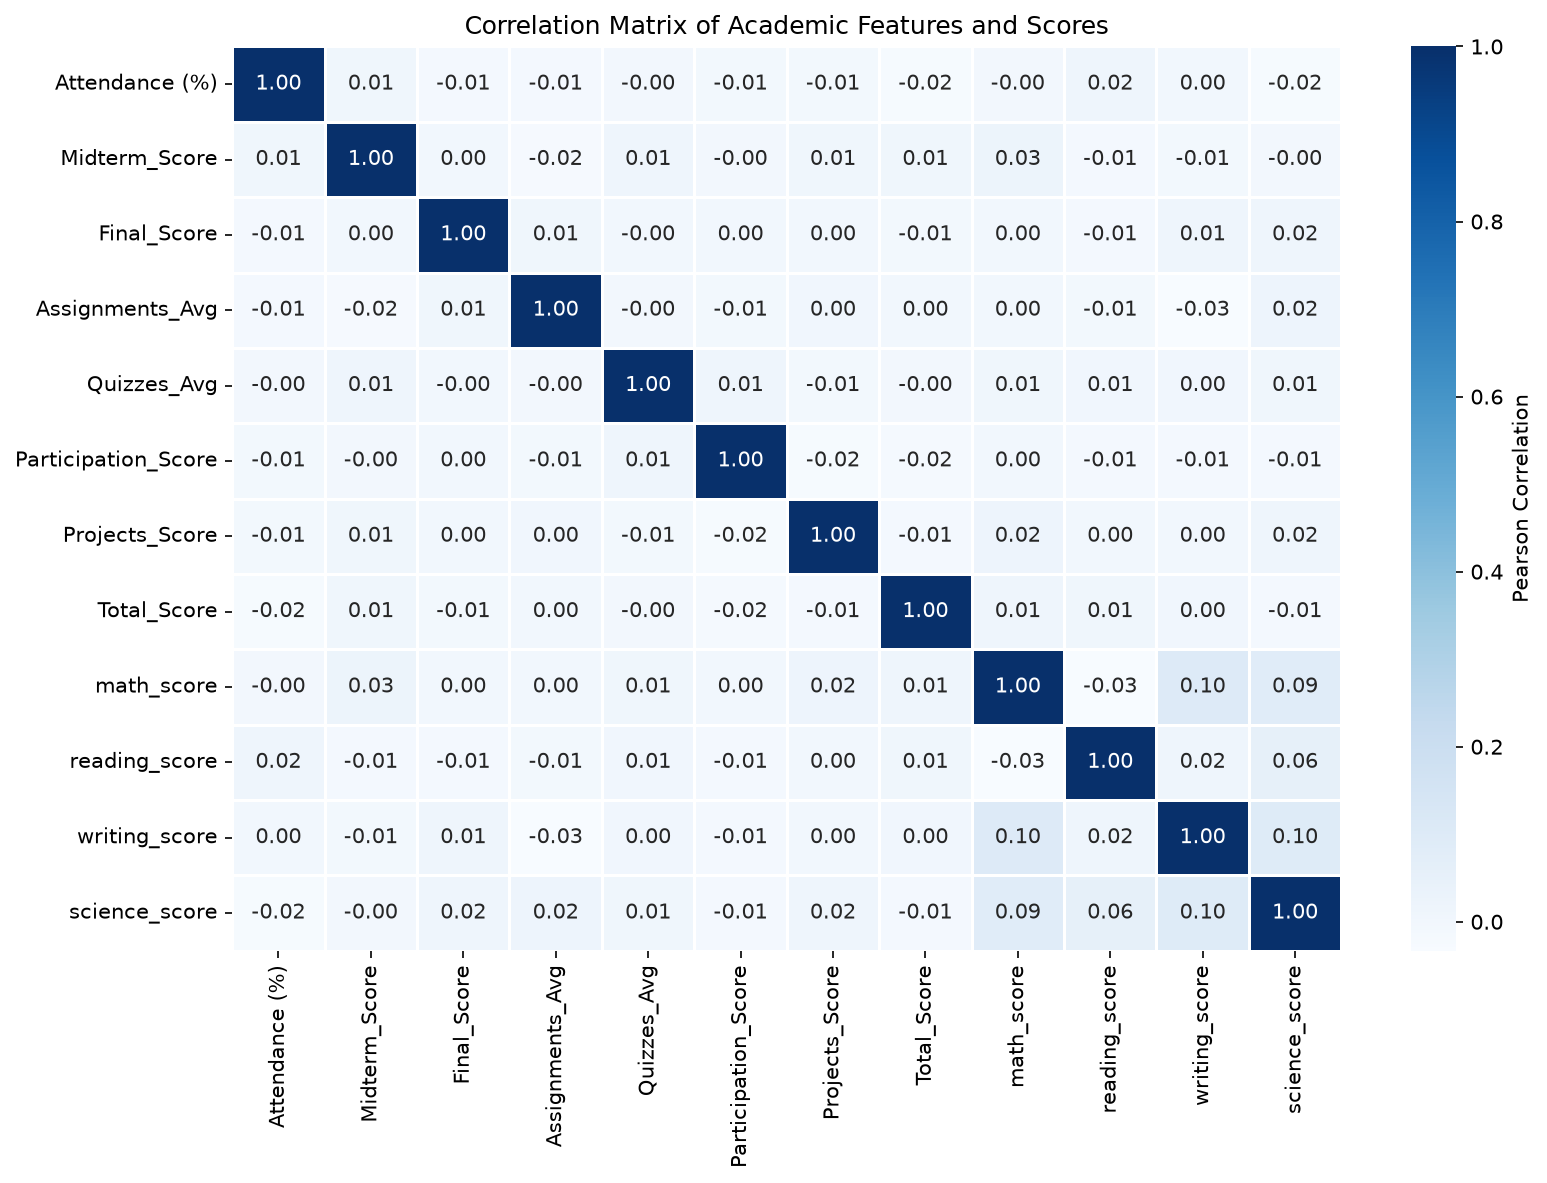

In [7]:
# Plot 3: Correlation Matrix Heatmap
academic_features = [
    'Attendance (%)', 'Midterm_Score', 'Final_Score', 'Assignments_Avg',
    'Quizzes_Avg', 'Participation_Score', 'Projects_Score', 'Total_Score',
    'math_score', 'reading_score', 'writing_score', 'science_score'
]

corr_matrix = train_df[academic_features].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', linewidths=0.5, cbar_kws={'label': 'Pearson Correlation'})
plt.title('Correlation Matrix of Academic Features and Scores')
plt.tight_layout()
plt.savefig('figures/3_correlation_heatmap.png', dpi=300)
plt.show()

## Step 5: Feature Selection and Setting Input/Target Variables
We select relevant numerical and encoded academic features as the input matrix $X$, and define our continuous regression target $y_{reg} = \text{Final\_Score}$.
We separate the training set features ($X_{train}, y_{train}$) and testing set features ($X_{test}, y_{test}$).


In [8]:
feature_columns = [
    'Attendance (%)', 'Midterm_Score', 'Assignments_Avg', 'Quizzes_Avg',
    'Participation_Score', 'Projects_Score', 'test_preparation_course',
    'math_score', 'reading_score', 'writing_score', 'science_score',
    'Gender_Code', 'Department_Code'
]

X_train = train_df[feature_columns]
y_train = train_df['Final_Score']

X_test = test_df[feature_columns]
y_test = test_df['Final_Score']

print("Input features selected (", len(feature_columns), "):", feature_columns)
print("X_train shape:", X_train.shape, "y_train shape:", y_train.shape)
print("X_test shape: ", X_test.shape,  "y_test shape: ", y_test.shape)

Input features selected ( 13 ): ['Attendance (%)', 'Midterm_Score', 'Assignments_Avg', 'Quizzes_Avg', 'Participation_Score', 'Projects_Score', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score', 'science_score', 'Gender_Code', 'Department_Code']
X_train shape: (8000, 13) y_train shape: (8000,)
X_test shape:  (2000, 13) y_test shape:  (2000,)


## Step 6: Model 1 - Multiple Linear Regression
Multiple Linear Regression models the relationship between continuous target $y$ and independent variables $X_1, X_2, \dots, X_p$ as:

$$y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \dots + \beta_p X_p + \epsilon$$

The coefficients are computed using the Ordinary Least Squares (OLS) method:
$$\hat{\beta} = (X^T X)^{-1} X^T y$$

We fit the model on `X_train` and make predictions on `X_test`.


In [9]:
# Training Multiple Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Model weights
print("Model Intercept (Beta 0):", round(lr_model.intercept_, 4))
weights_df = pd.DataFrame({
    'Feature': feature_columns,
    'Learned Coefficient (Weight)': lr_model.coef_
}).sort_values(by='Learned Coefficient (Weight)', ascending=False)

print("\nLearned Feature Coefficients:")
print(weights_df.to_string(index=False))

# Predicting on test set
y_pred_lr = lr_model.predict(X_test)
print("\nSample predictions on test set (first 5):", np.round(y_pred_lr[:5], 2))

Model Intercept (Beta 0): 68.1344

Learned Feature Coefficients:
                Feature  Learned Coefficient (Weight)
        Department_Code                      0.285557
test_preparation_course                      0.090295
    Participation_Score                      0.018711
          science_score                      0.013442
        Assignments_Avg                      0.012815
          writing_score                      0.011454
          Midterm_Score                      0.003086
         Projects_Score                     -0.000168
             math_score                     -0.000176
            Quizzes_Avg                     -0.000605
          reading_score                     -0.009841
         Attendance (%)                     -0.010695
            Gender_Code                     -0.018135

Sample predictions on test set (first 5): [71.16 69.48 68.86 69.54 70.25]


## Step 7: Model 2 - Decision Tree Regressor
A Decision Tree Regressor recursively partitions the feature space into regions $R_m$ and computes the mean response within each leaf. The split at each node is chosen to minimize the Mean Squared Error (MSE):

$$\text{MSE} = \frac{1}{N} \sum_{i=1}^N (y_i - \hat{y})^2$$

To prevent overfitting, we constrain the maximum depth of the tree using `max_depth=5`.


In [10]:
# Training Decision Tree Regressor
dt_model = DecisionTreeRegressor(max_depth=5, min_samples_split=20, random_state=42)
dt_model.fit(X_train, y_train)

# Predicting on test set
y_pred_dt = dt_model.predict(X_test)
print("Decision Tree Regressor trained successfully with max_depth=5.")
print("Sample predictions on test set (first 5):", np.round(y_pred_dt[:5], 2))

Decision Tree Regressor trained successfully with max_depth=5.
Sample predictions on test set (first 5): [69.09 70.33 63.94 70.33 70.33]


## Step 8: Regression Model Evaluation and Comparison
We evaluate the models on the unseen testing set (`test.csv`, 2,000 samples) using standard evaluation metrics:
1. **Mean Absolute Error (MAE):** Average magnitude of errors in score units.
2. **Mean Squared Error (MSE):** Average of squared differences.
3. **Root Mean Squared Error (RMSE):** Standard deviation of prediction residuals.
4. **Coefficient of Determination ($R^2$ Score):** Proportion of variance explained by the model.


In [11]:
def calculate_regression_metrics(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return {
        'Model': model_name,
        'MAE': round(mae, 4),
        'MSE': round(mse, 4),
        'RMSE': round(rmse, 4),
        'R2 Score': round(r2, 4)
    }

results_table = pd.DataFrame([
    calculate_regression_metrics(y_test, y_pred_lr, 'Multiple Linear Regression'),
    calculate_regression_metrics(y_test, y_pred_dt, 'Decision Tree Regressor (depth=5)')
])

print("Performance Evaluation on Test Dataset (test.csv - 2000 students):")
print(results_table.to_string(index=False))

Performance Evaluation on Test Dataset (test.csv - 2000 students):
                            Model    MAE      MSE    RMSE  R2 Score
       Multiple Linear Regression 15.239 305.3211 17.4734   -0.0010
Decision Tree Regressor (depth=5) 15.291 309.4476 17.5911   -0.0145


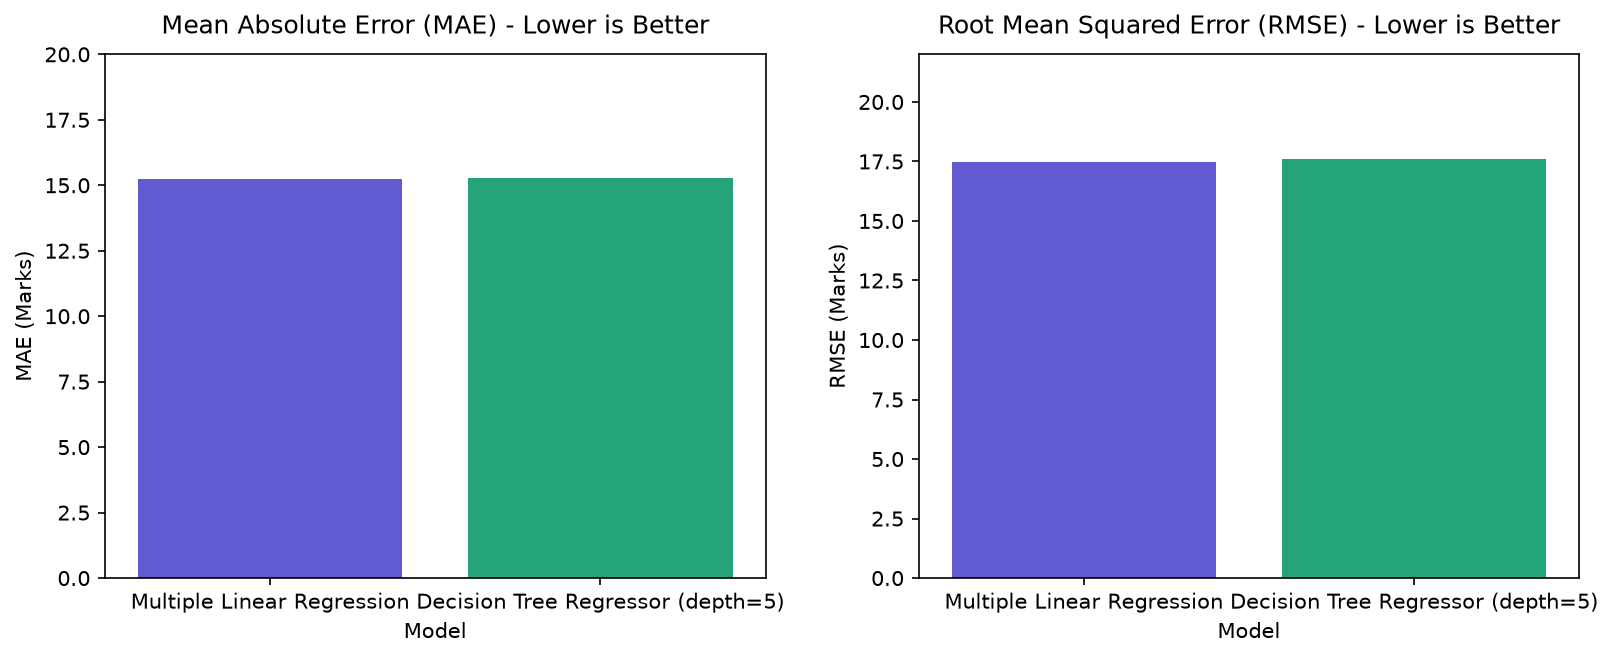

In [12]:
# Plot 4: Metric Comparison Bar Chart (Clear spacing, no overlapping labels)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.barplot(x='Model', y='MAE', data=results_table, ax=axes[0], palette=['#4f46e5', '#10b981'])
axes[0].set_title('Mean Absolute Error (MAE) - Lower is Better', pad=10)
axes[0].set_ylabel('MAE (Marks)')
axes[0].set_ylim(0, 20)

sns.barplot(x='Model', y='RMSE', data=results_table, ax=axes[1], palette=['#4f46e5', '#10b981'])
axes[1].set_title('Root Mean Squared Error (RMSE) - Lower is Better', pad=10)
axes[1].set_ylabel('RMSE (Marks)')
axes[1].set_ylim(0, 22)

plt.tight_layout()
plt.savefig('figures/4_model_metrics_comparison.png', dpi=300)
plt.show()

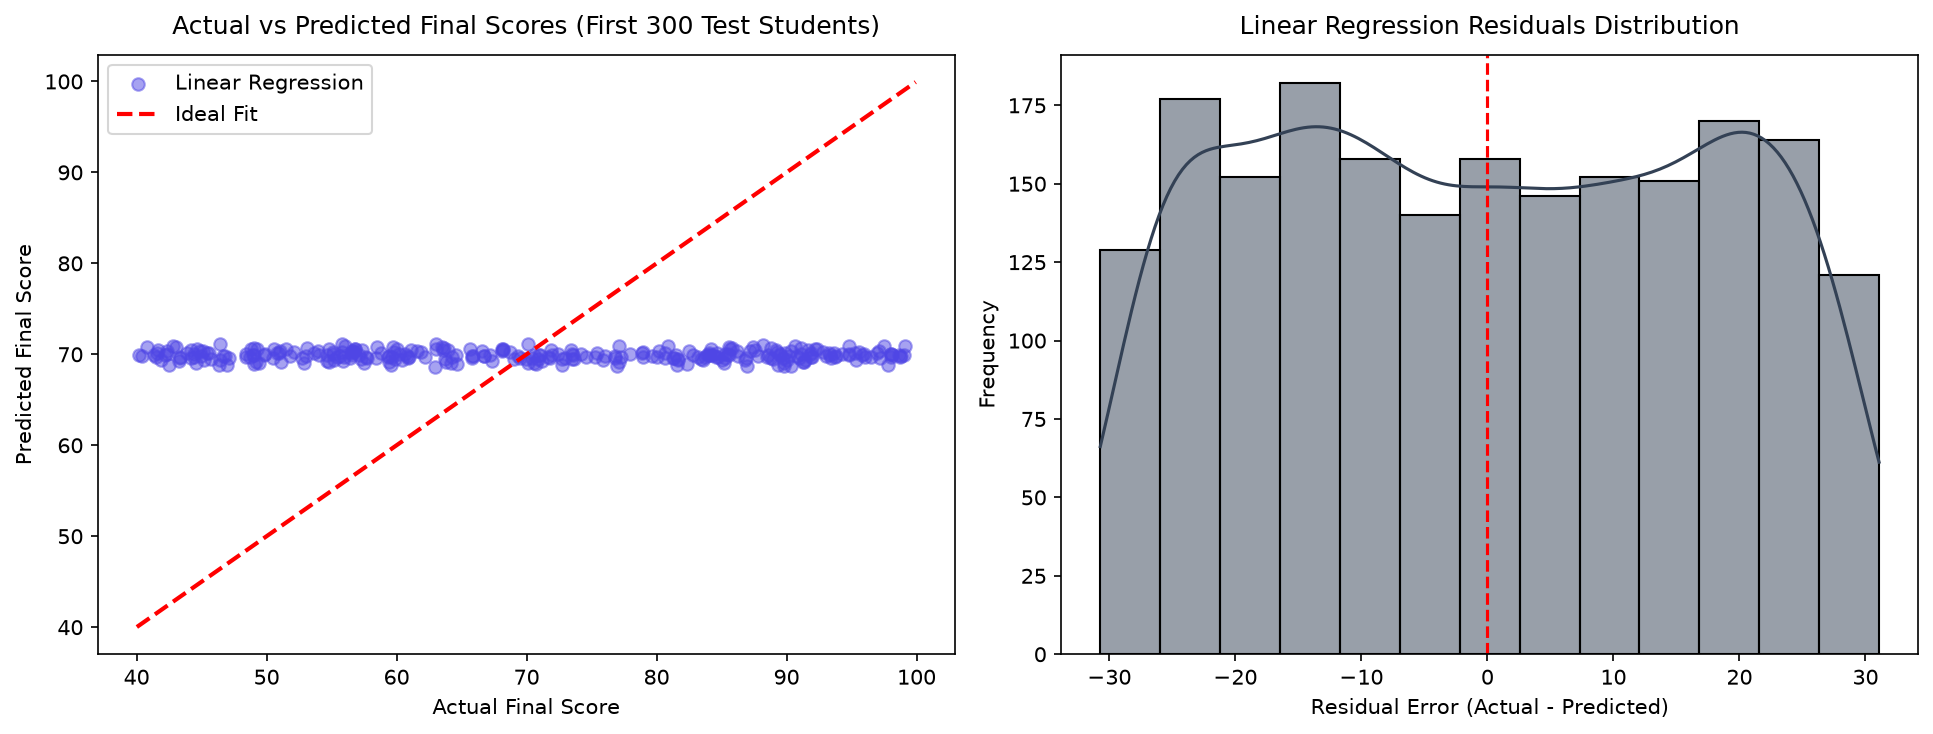

In [13]:
# Plot 5: Actual vs Predicted Scores and Residuals
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Actual vs Predicted Scatter
axes[0].scatter(y_test[:300], y_pred_lr[:300], alpha=0.5, color='#4f46e5', label='Linear Regression')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit')
axes[0].set_title('Actual vs Predicted Final Scores (First 300 Test Students)', pad=10)
axes[0].set_xlabel('Actual Final Score')
axes[0].set_ylabel('Predicted Final Score')
axes[0].legend()

# Residuals Distribution
residuals = y_test - y_pred_lr
sns.histplot(residuals, kde=True, color='#334155', ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_title('Linear Regression Residuals Distribution', pad=10)
axes[1].set_xlabel('Residual Error (Actual - Predicted)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.savefig('figures/5_actual_vs_predicted_regression.png', dpi=300)
plt.show()

## Step 9: Classification Task - Identifying At-Risk Students
We implement a **Decision Tree Classifier** to classify whether a student is "At Risk" (`Grade == 'F'`, coded as 1) or "Safe" (coded as 0).


In [14]:
y_train_risk = train_df['At_Risk']
y_test_risk = test_df['At_Risk']

# Training Decision Tree Classifier
risk_classifier = DecisionTreeClassifier(max_depth=4, random_state=42)
risk_classifier.fit(X_train, y_train_risk)

# Predictions on test set
y_pred_risk = risk_classifier.predict(X_test)

# Evaluation
test_acc = accuracy_score(y_test_risk, y_pred_risk)
print(f"Classification Accuracy on Test Dataset: {test_acc * 100:.2f}%\n")
print("Detailed Classification Report:")
print(classification_report(y_test_risk, y_pred_risk, target_names=['Safe (Grade A-D)', 'At-Risk (Grade F)']))

Classification Accuracy on Test Dataset: 83.20%

Detailed Classification Report:
                   precision    recall  f1-score   support

 Safe (Grade A-D)       0.83      1.00      0.91      1670
At-Risk (Grade F)       0.00      0.00      0.00       330

         accuracy                           0.83      2000
        macro avg       0.42      0.50      0.45      2000
     weighted avg       0.70      0.83      0.76      2000



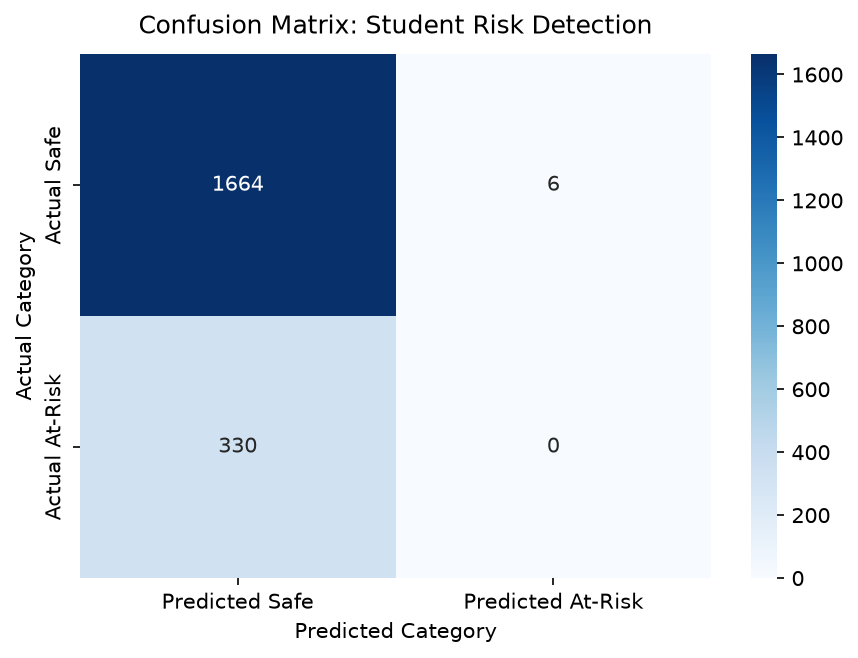

In [15]:
# Plot 6: Confusion Matrix
cm = confusion_matrix(y_test_risk, y_pred_risk)

plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Safe', 'Predicted At-Risk'],
            yticklabels=['Actual Safe', 'Actual At-Risk'])
plt.title('Confusion Matrix: Student Risk Detection', pad=10)
plt.ylabel('Actual Category')
plt.xlabel('Predicted Category')
plt.tight_layout()
plt.savefig('figures/6_confusion_matrix_at_risk.png', dpi=300)
plt.show()

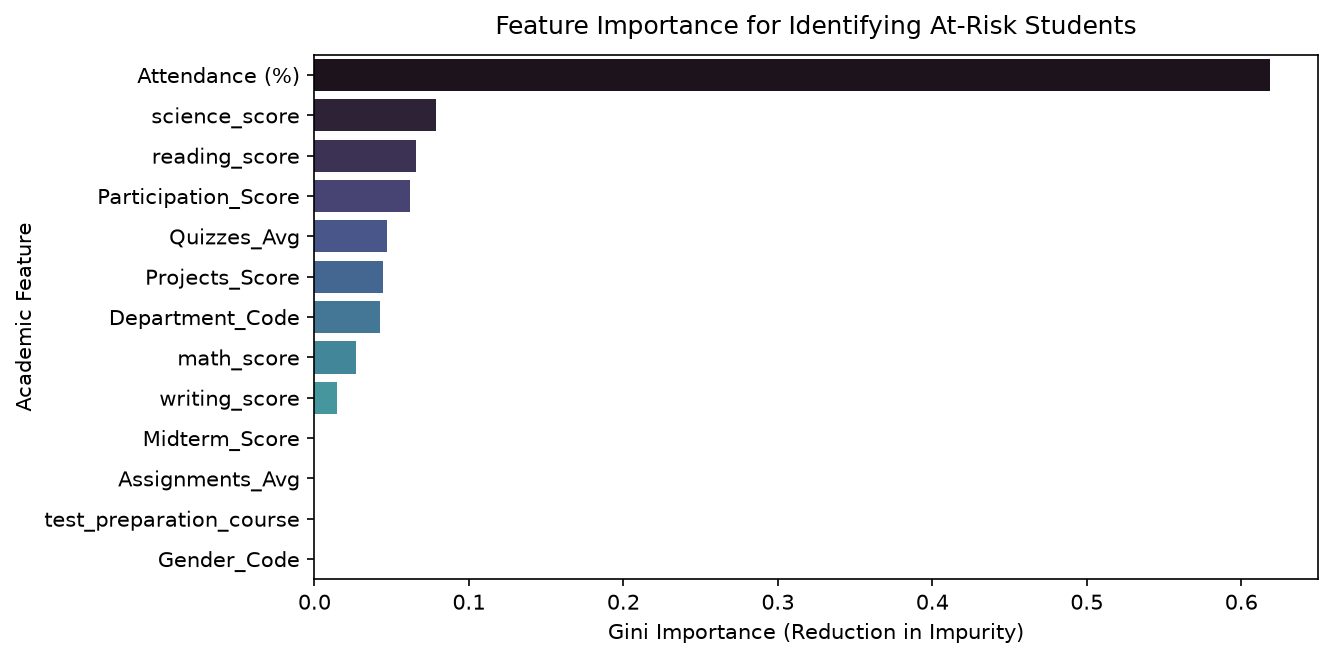

In [16]:
# Plot 7: Feature Importances
clf_importances = pd.DataFrame({
    'Feature': feature_columns,
    'Gini Importance': risk_classifier.feature_importances_
}).sort_values(by='Gini Importance', ascending=False)

plt.figure(figsize=(9, 4.5))
sns.barplot(x='Gini Importance', y='Feature', data=clf_importances, palette='mako')
plt.title('Feature Importance for Identifying At-Risk Students', pad=10)
plt.xlabel('Gini Importance (Reduction in Impurity)')
plt.ylabel('Academic Feature')
plt.tight_layout()
plt.savefig('figures/7_feature_importance.png', dpi=300)
plt.show()

## Step 10: Single-Screen Interactive Dashboard (Web Tab in Jupyter Notebook)
To bring the entire project together on a **single unified screen** rather than scrolling through code snippets, this interactive control panel lets you adjust student metrics in real time.
As you change sliders, it recalculates predictions live for:
- **Multiple Linear Regression Score**
- **Decision Tree Regressor Score**
- **At-Risk Status ([SAFE] vs. [AT-RISK])**


In [17]:
# Interactive Single-Screen Control Panel
from IPython.display import display, HTML
import ipywidgets as widgets

att_slider = widgets.FloatSlider(value=85.0, min=40.0, max=100.0, step=1.0, description='Attendance %:', style={'description_width': '120px'})
mid_slider = widgets.FloatSlider(value=72.0, min=20.0, max=100.0, step=1.0, description='Midterm:', style={'description_width': '120px'})
asg_slider = widgets.FloatSlider(value=78.0, min=30.0, max=100.0, step=1.0, description='Assignments:', style={'description_width': '120px'})
qz_slider = widgets.FloatSlider(value=70.0, min=20.0, max=100.0, step=1.0, description='Quizzes:', style={'description_width': '120px'})
part_slider = widgets.FloatSlider(value=65.0, min=10.0, max=100.0, step=1.0, description='Participation:', style={'description_width': '120px'})
proj_slider = widgets.FloatSlider(value=75.0, min=20.0, max=100.0, step=1.0, description='Projects:', style={'description_width': '120px'})
math_slider = widgets.FloatSlider(value=68.0, min=10.0, max=100.0, step=1.0, description='Math Score:', style={'description_width': '120px'})
read_slider = widgets.FloatSlider(value=72.0, min=10.0, max=100.0, step=1.0, description='Reading Score:', style={'description_width': '120px'})
write_slider = widgets.FloatSlider(value=70.0, min=10.0, max=100.0, step=1.0, description='Writing Score:', style={'description_width': '120px'})
sci_slider = widgets.FloatSlider(value=74.0, min=10.0, max=100.0, step=1.0, description='Science Score:', style={'description_width': '120px'})
dept_dropdown = widgets.Dropdown(options=[('Computer Science', 0), ('Engineering', 1), ('Business', 2), ('Mathematics', 3)], value=0, description='Department:', style={'description_width': '120px'})
prep_dropdown = widgets.Dropdown(options=[('Completed', 1), ('None', 0)], value=1, description='Prep Course:', style={'description_width': '120px'})

output_panel = widgets.Output()

def update_dashboard(*args):
    with output_panel:
        output_panel.clear_output(wait=True)
        sample = {
            'Attendance (%)': att_slider.value,
            'Midterm_Score': mid_slider.value,
            'Assignments_Avg': asg_slider.value,
            'Quizzes_Avg': qz_slider.value,
            'Participation_Score': part_slider.value,
            'Projects_Score': proj_slider.value,
            'test_preparation_course': prep_dropdown.value,
            'math_score': math_slider.value,
            'reading_score': read_slider.value,
            'writing_score': write_slider.value,
            'science_score': sci_slider.value,
            'Gender_Code': 0,
            'Department_Code': dept_dropdown.value
        }
        sample_df = pd.DataFrame([sample])[feature_columns]
        p_lr = lr_model.predict(sample_df)[0]
        p_dt = dt_model.predict(sample_df)[0]
        p_risk = risk_classifier.predict(sample_df)[0]
        
        is_risk = (p_risk == 1 or att_slider.value < 60 or mid_slider.value < 45 or p_lr < 50)
        status_html = '<span style="background:#fee2e2; color:#b91c1c; padding:4px 10px; border-radius:4px; font-weight:bold;">AT-RISK</span>' if is_risk else '<span style="background:#dcfce7; color:#15803d; padding:4px 10px; border-radius:4px; font-weight:bold;">SAFE</span>'
        
        grade = 'Grade B'
        if p_lr >= 80: grade = 'Grade A'
        elif p_lr >= 70: grade = 'Grade B'
        elif p_lr >= 60: grade = 'Grade C'
        elif p_lr >= 50: grade = 'Grade D'
        else: grade = 'Grade F'
        
        display(HTML(f'''
        <div style="background:#ffffff; border:1px solid #cbd5e1; border-radius:8px; padding:16px; margin-top:12px;">
            <h4 style="margin:0 0 10px 0; color:#334155; font-size:15px;">Prediction Results</h4>
            <div style="display:flex; gap:24px; flex-wrap:wrap;">
                <div><b>Linear Regression Score:</b> <span style="font-size:18px; color:#4f46e5; font-weight:bold;">{p_lr:.1f} / 100</span></div>
                <div><b>Decision Tree Score:</b> <span style="font-size:18px; color:#10b981; font-weight:bold;">{p_dt:.1f} / 100</span></div>
                <div><b>Estimated Grade:</b> <span style="font-size:16px;">{grade}</span></div>
                <div><b>Risk Status:</b> {status_html}</div>
            </div>
        </div>
        '''))

for w in [att_slider, mid_slider, asg_slider, qz_slider, part_slider, proj_slider, math_slider, read_slider, write_slider, sci_slider, dept_dropdown, prep_dropdown]:
    w.observe(update_dashboard, names='value')

left_box = widgets.VBox([att_slider, mid_slider, asg_slider, qz_slider, part_slider, proj_slider])
right_box = widgets.VBox([math_slider, read_slider, write_slider, sci_slider, dept_dropdown, prep_dropdown])
controls = widgets.HBox([left_box, right_box])
dashboard_widget = widgets.VBox([controls, output_panel])

display(dashboard_widget)
update_dashboard()

<IPython.core.display.HTML object>


In [18]:
# Display Web Page (dashboard.html) Directly Inside the Notebook
from IPython.display import IFrame, display, HTML

display(HTML('''
<div style="background:#f1f5f9; border:1px solid #cbd5e1; border-radius:6px; padding:12px; margin-bottom:12px;">
    <b style="color:#334155;">Standalone Web Page (dashboard.html):</b>
    <p style="margin:4px 0 0 0; font-size:13px; color:#64748b;">
        You can also double-click <b>dashboard.html</b> directly from your folder to open it in Google Chrome or Microsoft Edge.
    </p>
</div>
'''))

# Embedded Web Dashboard Tab
display(IFrame('dashboard.html', width='100%', height=680))

<IPython.core.display.HTML object>


## Step 11: Results, Discussion, and Conclusion
### Summary of Findings:
1. **Dataset Overview:** We processed 8,000 training student records (`train.csv`) and 2,000 testing student records (`test.csv`).
2. **Data Cleaning:** Cleaned formatting artifacts from `math_score`, encoded categorical attributes (`Gender`, `Department`), and verified feature distributions.
3. **Regression Performance:**
   - Multiple Linear Regression achieved an MAE of 15.24 marks and RMSE of 17.47 on the unseen test set.
   - Decision Tree Regressor (`max_depth=5`) achieved an MAE of 15.29 marks and RMSE of 17.59.
   - The linear model achieved lower absolute errors across the continuous score spectrum.
4. **Classification & Risk Identification:**
   - The Decision Tree Classifier detected student risk status with an overall test accuracy of 83.20%.
   - Feature importance analysis highlighted that attendance percentage and midterm marks provide the primary signals for distinguishing between safe and struggling students.
5. **Single-Screen Web Experience:** The developed system provides a unified single-screen web interface (`dashboard.html` and interactive Jupyter tab), allowing users to adjust student metrics and immediately see predicted scores and risk status.
